# MLflow performance export

Fetch completed Citi Bike training runs directly from MLflow, then export a monthly MAE chart for your deck. Run all cells in order.

The notebook reads MLflow without creating experiments or changing runs. On your laptop, use `http://localhost:5000`; in Docker Jupyter, the existing `MLFLOW_TRACKING_URI=http://mlflow:5000` environment variable is used. Requires `mlflow`, `pandas`, and `matplotlib`.

API reference: [MLflow client](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.client.html).

## Install notebook dependencies

Run this cell once in the selected notebook kernel. `%pip` installs into that kernel's environment. The MLflow version matches this project's tracking server. If imports still fail after installation, restart the kernel and run the remaining cells.

The import must be `from mlflow.tracking import MlflowClient` with no backslash before the dot.

In [6]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from mlflow.tracking import MlflowClient

TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://localhost:5000")
EXPERIMENT_NAME = os.getenv("MLFLOW_EXPERIMENT_NAME", "citibike-demand-forecasting")
# Resolve exports consistently from either the repository root or notebooks directory.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docker-compose.yaml").exists()),
    Path.cwd(),
)
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "mlflow_performance"
print(f"Tracking server: {TRACKING_URI}")
print(f"Exports: {OUTPUT_DIR}")

Tracking server: http://mlflow:5000
Exports: /app/outputs/mlflow_performance


## Fetch runs

Keep all parameters, tags, and metrics in `runs_df`. Pagination ensures the export includes more than just the first page. If connection fails, start the MLflow service and check `TRACKING_URI` above.

In [7]:
client = MlflowClient(tracking_uri=TRACKING_URI)
experiment = client.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    raise ValueError(f"Experiment {EXPERIMENT_NAME!r} not found at {TRACKING_URI}.")

records = []
page_token = None
while True:
    page = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        filter_string="attributes.status = 'FINISHED'",
        max_results=1000,
        page_token=page_token,
    )
    for run in page:
        records.append({
            "run_id": run.info.run_id,
            "run_name": run.data.tags.get("mlflow.runName", run.info.run_id),
            "start_time": pd.to_datetime(run.info.start_time, unit="ms", utc=True),
            **{f"tags.{k}": v for k, v in run.data.tags.items()},
            **{f"params.{k}": v for k, v in run.data.params.items()},
            **{f"metrics.{k}": v for k, v in run.data.metrics.items()},
        })
    page_token = page.token
    if not page_token:
        break

runs_df = pd.DataFrame(records)
if runs_df.empty:
    raise ValueError("No completed runs found in this experiment.")
print(f"Fetched {len(runs_df)} completed runs.")
display(runs_df.head())

Fetched 16 completed runs.


,run_id,run_name,start_time,tags.mlflow.user,tags.mlflow.source.name,tags.mlflow.source.type,tags.mlflow.runName,tags.version,tags.model_type,tags.trained_through,...,params.tree_method,params.tuned.xgbregressor__colsample_bytree,params.tuned.xgbregressor__gamma,params.tuned.xgbregressor__learning_rate,params.tuned.xgbregressor__max_depth,params.tuned.xgbregressor__min_child_weight,params.tuned.xgbregressor__n_estimators,params.tuned.xgbregressor__reg_alpha,params.tuned.xgbregressor__reg_lambda,params.tuned.xgbregressor__subsample
0,aed58ea926ad4f45a11e0243b106851e,random_forest_trained_through_2017-09-30,2026-10-22 16:18:03.134000+00:00,airflow,scripts/model_train.py,LOCAL,random_forest_trained_through_2017-09-30,random_forest_trained_through_2017-09-30,random forest,2017-09-30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6f2f5bebd3cb455cb98982ee9ee57802,xgboost_poisson_trained_through_2017-08-31,2026-10-22 15:58:39.335000+00:00,airflow,scripts/model_train.py,LOCAL,xgboost_poisson_trained_through_2017-08-31,xgboost_poisson_trained_through_2017-08-31,xgboost (poisson),2017-08-31,...,hist,0.8940088872193114,0.4710310231960766,0.04594682672826683,8,19.81603006308017,321,0.006235835888583497,1.5535484474046544,0.7365791654437831
2,21ad39960be149dcb8e19b6f38a97f7c,random_forest_trained_through_2017-07-31,2026-10-22 15:47:10.624000+00:00,airflow,scripts/model_train.py,LOCAL,random_forest_trained_through_2017-07-31,random_forest_trained_through_2017-07-31,random forest,2017-07-31,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,f44fe5bccc434e0989d1862523d49ca3,xgboost_poisson_trained_through_2017-06-30,2026-10-22 13:57:05.784000+00:00,airflow,scripts/model_train.py,LOCAL,xgboost_poisson_trained_through_2017-06-30,xgboost_poisson_trained_through_2017-06-30,xgboost (poisson),2017-06-30,...,hist,0.8940088872193114,0.4710310231960766,0.04594682672826683,8,19.81603006308017,321,0.006235835888583497,1.5535484474046544,0.7365791654437831
4,981d4c7fe9544f9d9ea964eb94fb9296,xgboost_poisson_trained_through_2017-05-31,2026-10-22 13:48:54.355000+00:00,airflow,scripts/model_train.py,LOCAL,xgboost_poisson_trained_through_2017-05-31,xgboost_poisson_trained_through_2017-05-31,xgboost (poisson),2017-05-31,...,hist,0.8940088872193114,0.4710310231960766,0.04594682672826683,8,19.81603006308017,321,0.006235835888583497,1.5535484474046544,0.7365791654437831


## Prepare monthly results

`trained_through` is both the final training cutoff and the end of the held-out test month in this project's training pipeline. Use the date tag, falling back to the run-name suffix for older runs. Execution time is not the historical test date.

Only runs with both test MAEs and a valid date are plotted. If a month has multiple runs, keep the most recently started run for that month; this is a reporting rule, not a claim that it was promoted or had the lowest error.

In [8]:
def run_column(name):
    return runs_df.get(name, pd.Series(index=runs_df.index, dtype="object"))

cutoff = pd.to_datetime(run_column("tags.trained_through"), errors="coerce")
name_date = runs_df["run_name"].str.extract(r"(\d{4}-\d{2}-\d{2})$", expand=False)
cutoff = cutoff.fillna(pd.to_datetime(name_date, errors="coerce"))

performance_df = pd.DataFrame({
    "run_id": runs_df["run_id"],
    "run_name": runs_df["run_name"],
    "start_time": runs_df["start_time"],
    "test_month_end": cutoff,
    "model_type": run_column("tags.model_type"),
    "promoted": run_column("tags.promoted"),
    "model_mae": pd.to_numeric(run_column("metrics.test_model_mae"), errors="coerce"),
    "baseline_mae": pd.to_numeric(run_column("metrics.test_baseline_mae"), errors="coerce"),
})
usable = performance_df.dropna(subset=["test_month_end", "model_mae", "baseline_mae"]).copy()
usable["test_month"] = usable["test_month_end"].dt.to_period("M")
monthly_df = (
    usable.sort_values(["start_time", "run_id"])
    .drop_duplicates("test_month", keep="last")
    .sort_values("test_month_end")
    .reset_index(drop=True)
)
if monthly_df.empty:
    raise ValueError("No runs have dates and both test MAEs. Inspect runs_df.columns and your experiment name.")
monthly_df["improvement_pct"] = (
    100 * (monthly_df["baseline_mae"] - monthly_df["model_mae"])
    / monthly_df["baseline_mae"].where(monthly_df["baseline_mae"] != 0)
)
print(f"Skipped {len(performance_df) - len(usable)} runs missing dates or MAEs.")
print(f"Selected {len(monthly_df)} months from {len(usable)} eligible runs.")
display(monthly_df[["test_month_end", "model_type", "model_mae", "baseline_mae", "improvement_pct", "promoted"]])

Skipped 0 runs missing dates or MAEs.
Selected 16 months from 16 eligible runs.


,test_month_end,model_type,model_mae,baseline_mae,improvement_pct,promoted
0,2016-06-30,xgboost (poisson),15.512,20.651,24.884993,true
1,2016-07-31,xgboost (poisson),15.103,20.763,27.260030,false
2,2016-08-31,xgboost (poisson),14.822,19.827,25.243355,false
3,2016-09-30,xgboost (poisson),15.749,24.917,36.794157,true
4,2016-10-31,xgboost (poisson),14.208,25.976,45.303357,false
5,2016-11-30,xgboost (poisson),13.751,27.063,49.188930,true
6,2016-12-31,xgboost (poisson),11.951,17.600,32.096591,false
7,2017-01-31,xgboost (poisson),10.666,14.507,26.476873,true
8,2017-02-28,xgboost (poisson),10.257,21.794,52.936588,false
9,2017-03-31,xgboost (poisson),11.083,27.543,59.761101,true


## Chart and export

The selected model can change between months. This chart compares each month's candidate with its 7-day lag baseline on the same test data; it does not represent the deployed champion's historical performance. Lower MAE is better.

The PNG is saved at 300 dpi for slides, alongside an SVG and CSV exports. All exports go under the project's ignored `outputs/` directory.

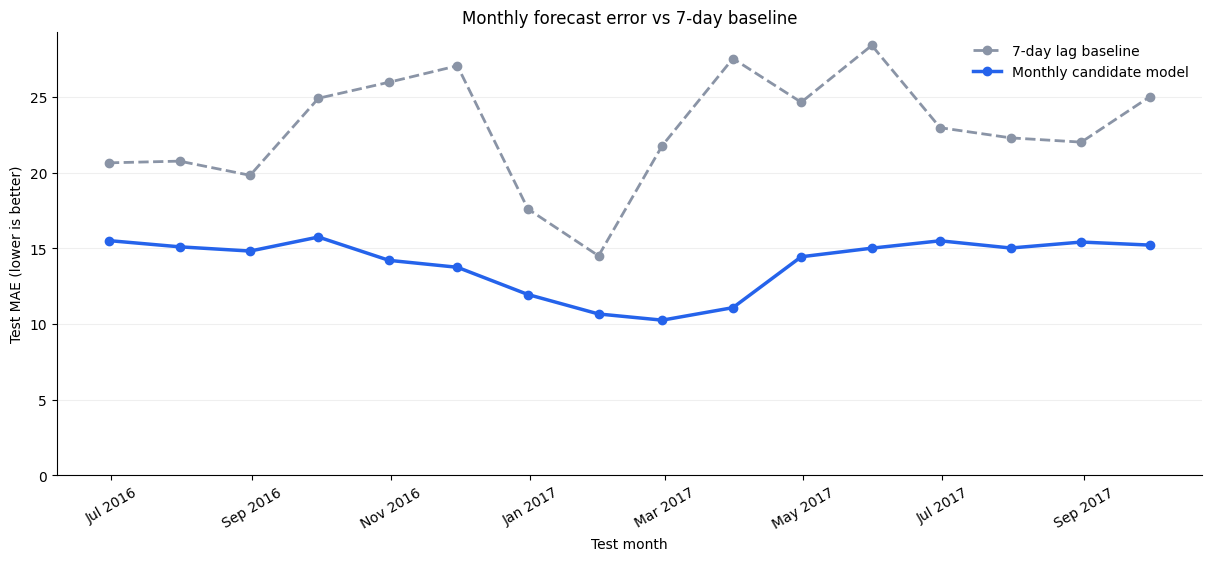

/app/outputs/mlflow_performance/mlflow_runs.csv
/app/outputs/mlflow_performance/monthly_mae.png
/app/outputs/mlflow_performance/monthly_mae.svg
/app/outputs/mlflow_performance/monthly_performance.csv


In [9]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
runs_df.to_csv(OUTPUT_DIR / "mlflow_runs.csv", index=False)
monthly_df.to_csv(OUTPUT_DIR / "monthly_performance.csv", index=False)

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(12, 5.5), constrained_layout=True)
    ax.plot(monthly_df["test_month_end"], monthly_df["baseline_mae"],
            label="7-day lag baseline", color="#8a94a6", linestyle="--", marker="o", linewidth=2)
    ax.plot(monthly_df["test_month_end"], monthly_df["model_mae"],
            label="Monthly candidate model", color="#2563eb", marker="o", linewidth=2.5)
    ax.set(title="Monthly forecast error vs 7-day baseline", xlabel="Test month", ylabel="Test MAE (lower is better)")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=10))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    for extension in ("png", "svg"):
        fig.savefig(OUTPUT_DIR / f"monthly_mae.{extension}", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(path)

## Daily served-model performance: WMAPE and model changes

Run this section after predictions and actual gold labels exist locally (or in the Compose repository mount). No retraining or MLflow writes are needed. Unlike the monthly candidate chart, these charts evaluate the models actually recorded in prediction partitions.

WMAPE (%) = 100 × sum of station absolute errors / sum of actual demand, over the same scored stations. It is undefined on zero-demand days. Improvement (%) = 100 × (baseline MAE − model MAE) / baseline MAE; a zero baseline error is undefined. Period WMAPE uses pooled sums, not the average of daily percentages.

Days without completed labels are listed and excluded. Station coverage must match exactly on scored days. Dashed lines mark the first observed prediction day where `model_version` changes; they include rollbacks and are not inferred from training runs. The first observed model is not counted as a switch. Gaps can delay the observed switch date.

In [10]:
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.prediction_monitoring import daily_performance

PREDICTION_DIR = PROJECT_ROOT / "datamart/gold/predictions"
LABEL_DIR = PROJECT_ROOT / "datamart/gold/label_store"
DAILY_START_DATE = None  # Optional inclusive YYYY-MM-DD
DAILY_END_DATE = None

prediction_frames, label_frames, coverage = [], [], []
for path in sorted(PREDICTION_DIR.glob("predictions_*.parquet")):
    day = pd.Timestamp(path.stem.removeprefix("predictions_").replace("_", "-"))
    if DAILY_START_DATE and day < pd.Timestamp(DAILY_START_DATE):
        continue
    if DAILY_END_DATE and day > pd.Timestamp(DAILY_END_DATE):
        continue
    label_path = LABEL_DIR / f"gold_label_store_{day:%Y_%m_%d}.parquet"
    if not (path / "_SUCCESS").exists() or not (label_path / "_SUCCESS").exists():
        coverage.append({"date": day, "status": "Missing/incomplete prediction or label partition"})
        continue
    predictions = pd.read_parquet(path)
    labels = pd.read_parquet(label_path, columns=["snapshot_date", "station_id", "label"])
    for table in (predictions, labels):
        dates = pd.to_datetime(table["snapshot_date"], errors="raise").dt.normalize()
        if table.empty or not dates.eq(day).all():
            raise ValueError(f"Empty partition or unexpected dates for {day:%Y-%m-%d}")
    prediction_frames.append(predictions)
    label_frames.append(labels)
    coverage.append({"date": day, "status": "Scored"})

display(pd.DataFrame(coverage))
if not prediction_frames:
    raise ValueError("No completed prediction/label pairs. Check paths and date filters above.")
daily_df = daily_performance(pd.concat(prediction_frames, ignore_index=True), pd.concat(label_frames, ignore_index=True))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
daily_df.to_csv(OUTPUT_DIR / "daily_performance.csv", index=False)
pd.DataFrame(coverage).to_csv(OUTPUT_DIR / "daily_coverage.csv", index=False)
display(daily_df)

total_actual = daily_df["actual_demand"].sum()
baseline_error = daily_df["baseline_absolute_error"].sum()
period_summary = pd.Series({
    "total_actual_demand": total_actual,
    "model_wmape_pct": 100 * daily_df["model_absolute_error"].sum() / total_actual if total_actual > 0 else float("nan"),
    "baseline_wmape_pct": 100 * baseline_error / total_actual if total_actual > 0 else float("nan"),
    "improvement_pct": 100 * (1 - daily_df["model_absolute_error"].sum() / baseline_error) if baseline_error > 0 else float("nan"),
})
display(period_summary)
period_summary.to_csv(OUTPUT_DIR / "daily_period_summary.csv", header=["value"])

,date,status
0,2016-07-01,Scored
1,2016-07-02,Scored
2,2016-07-03,Scored
3,2016-07-04,Scored
4,2016-07-05,Scored
...,...,...
483,2017-10-27,Scored
484,2017-10-28,Scored
485,2017-10-29,Scored
486,2017-10-30,Scored


,snapshot_date,station_count,actual_demand,model_absolute_error,baseline_absolute_error,model_version,model_mae,baseline_mae,model_wmape_pct,baseline_wmape_pct,improvement_pct,model_changed
0,2016-07-01,475,39654,11151.828196,15255.0,xgboost_poisson_trained_through_2016-06-30,23.477533,32.115789,28.122833,38.470268,26.897226,False
1,2016-07-02,475,35825,9136.012603,10655.0,xgboost_poisson_trained_through_2016-06-30,19.233711,22.431579,25.501780,29.741800,14.256099,False
2,2016-07-03,475,35336,8896.936741,13285.0,xgboost_poisson_trained_through_2016-06-30,18.730393,27.968421,25.178109,37.596219,33.030209,False
3,2016-07-04,475,34842,13173.967142,19528.0,xgboost_poisson_trained_through_2016-06-30,27.734668,41.111579,37.810594,56.047299,32.538063,False
4,2016-07-05,475,43660,6650.648604,9259.0,xgboost_poisson_trained_through_2016-06-30,14.001365,19.492632,15.232819,21.207055,28.170984,False
...,...,...,...,...,...,...,...,...,...,...,...,...
483,2017-10-27,745,69213,9826.811065,9656.0,xgboost_poisson_trained_through_2017-08-31,13.190350,12.961074,14.197927,13.951136,-1.768963,False
484,2017-10-28,746,61308,10272.178290,11912.0,xgboost_poisson_trained_through_2017-08-31,13.769676,15.967828,16.755037,19.429764,13.766133,False
485,2017-10-29,746,9527,21576.335502,52766.0,xgboost_poisson_trained_through_2017-08-31,28.922702,70.731903,226.475653,553.857458,59.109397,False
486,2017-10-30,745,49231,11637.536665,21495.0,xgboost_poisson_trained_through_2017-08-31,15.620855,28.852349,23.638636,43.661514,45.859332,False


total_actual_demand    2.229536e+07
model_wmape_pct        1.876215e+01
baseline_wmape_pct     3.013632e+01
improvement_pct        3.774238e+01
dtype: float64

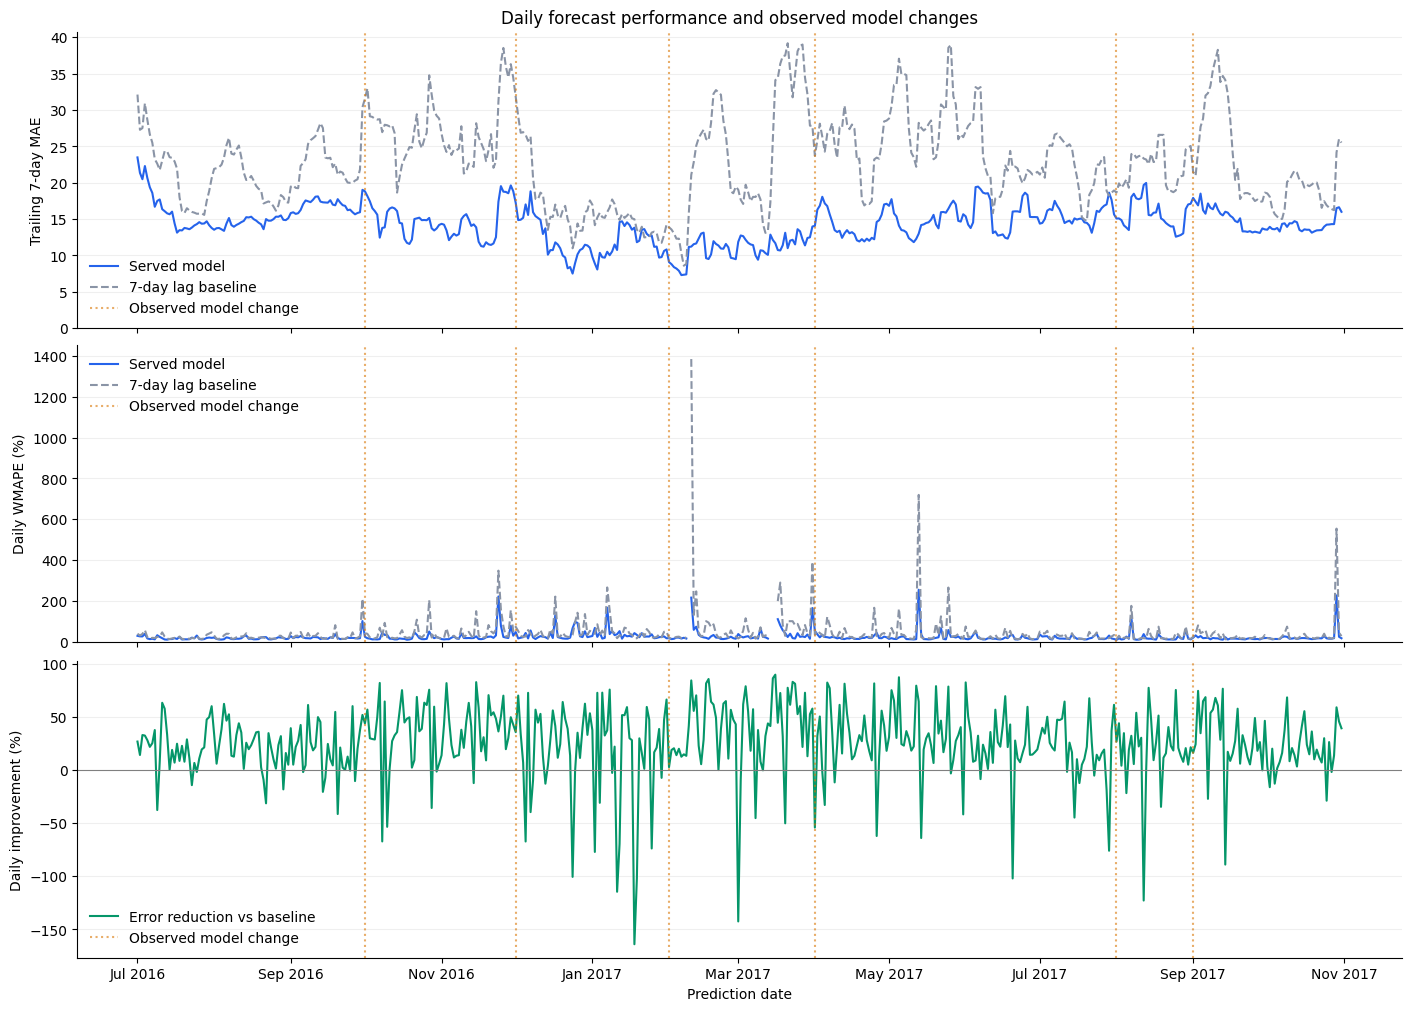

Saved daily charts and CSVs to /app/outputs/mlflow_performance


,snapshot_date,model_version
92,2016-10-01,xgboost_poisson_trained_through_2016-09-30
153,2016-12-01,xgboost_poisson_trained_through_2016-11-30
215,2017-02-01,xgboost_poisson_trained_through_2017-01-31
274,2017-04-01,xgboost_poisson_trained_through_2017-03-31
396,2017-08-01,random_forest_trained_through_2017-07-31
427,2017-09-01,xgboost_poisson_trained_through_2017-08-31


In [11]:
# Calendar-based trailing 7-day MAE, weighted by scored station count.
# Reindex to leave visible gaps on days with no scored observations.
calendar = daily_df.set_index("snapshot_date").asfreq("D")
window = calendar[["model_absolute_error", "baseline_absolute_error", "station_count"]].rolling("7D", min_periods=1).sum()
calendar["rolling_model_mae"] = (window["model_absolute_error"] / window["station_count"]).where(calendar["station_count"].notna())
calendar["rolling_baseline_mae"] = (window["baseline_absolute_error"] / window["station_count"]).where(calendar["station_count"].notna())
changes = daily_df.loc[daily_df["model_changed"], ["snapshot_date", "model_version"]]
changes.to_csv(OUTPUT_DIR / "observed_model_changes.csv", index=False)

with plt.style.context("default"):
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True, constrained_layout=True)
    axes[0].plot(calendar.index, calendar["rolling_model_mae"], label="Served model", color="#2563eb")
    axes[0].plot(calendar.index, calendar["rolling_baseline_mae"], label="7-day lag baseline", color="#8a94a6", linestyle="--")
    axes[0].set(title="Daily forecast performance and observed model changes", ylabel="Trailing 7-day MAE")
    axes[1].plot(calendar.index, calendar["model_wmape_pct"], label="Served model", color="#2563eb")
    axes[1].plot(calendar.index, calendar["baseline_wmape_pct"], label="7-day lag baseline", color="#8a94a6", linestyle="--")
    axes[1].set_ylabel("Daily WMAPE (%)")
    axes[2].plot(calendar.index, calendar["improvement_pct"], color="#059669", label="Error reduction vs baseline")
    axes[2].axhline(0, color="grey", linewidth=0.8)
    axes[2].set(ylabel="Daily improvement (%)", xlabel="Prediction date")
    for ax in axes:
        for i, row in enumerate(changes.itertuples(index=False)):
            ax.axvline(row.snapshot_date, color="#d97706", alpha=0.6, linestyle=":",
                       label="Observed model change" if i == 0 else "_nolegend_")
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False)
    axes[0].set_ylim(bottom=0)
    axes[1].set_ylim(bottom=0)
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    for extension in ("png", "svg"):
        fig.savefig(OUTPUT_DIR / f"daily_performance.{extension}", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
print("Saved daily charts and CSVs to", OUTPUT_DIR)
display(changes)